# Wyniki końcowe – pytanie badawcze i hipotezy H1–H4

**Pytanie główne (README):** *Czy istotne wydarzenia społeczne, polityczne i medialne związane z migrantami są powiązane
ze zmianami poziomu mowy nienawiści w polskojęzycznych mediach społecznościowych?*

Notebook zbiera wyniki wszystkich etapów i liczy testy z tabeli w README:

| Hipoteza | Co sprawdzamy | Test |
|---|---|---|
| **H1** wpływ wydarzeń | czy poziom hate po wydarzeniu różni się od poziomu przed | Wilcoxon (pary przed/po) + wielkość efektu; dodatkowo regresja logistyczna z klastrami po wątkach i metaanaliza (jak w analizach zespołu) |
| **H2** charakter wydarzenia | czy zmiana zależy od typu wydarzenia | Kruskal–Wallis → post-hoc Dunn + Holm |
| **H3** trwałość efektu | czy zmiana jest największa tuż po wydarzeniu i potem słabnie; po ilu dniach wraca do baseline | Friedman → post-hoc Wilcoxon + Holm; każde okno vs baseline (Wilcoxon + Holm) |
| **H4** różnice między platformami | czy poziom i reakcja różnią się między Wykopem, Bluesky i YouTube | Kruskal–Wallis → post-hoc Dunn + Holm (+ Friedman dla wydarzeń obecnych na 3 platformach) |

**Jednostka analizy:** para *wydarzenie × platforma* (pary z < `MIN_EVENT_N` komentarzami pomijane; liczba par w sekcji 0).
Wyniki raportowane: **osobno** (każde wydarzenie na każdej platformie), **zagregowane per platforma** (wszystkie wydarzenia
platformy) i **zagregowane per wydarzenie** (wszystkie platformy dla danego wydarzenia).

**Etykieta:** `hate` z najlepszego klasyfikatora wg gold standardu (`reports/gold_model_eval/best_model.json`) – słownik obelg
**albo** model, na komentarzach z filtru tematycznego zespołu. Etykiety LLM zespołu (`hate`, `hate_migrant`, `migrant`)
są dołączane, jeśli `data/interim/<platforma>/<wydarzenie>/labeled/` jest pobrane z DVC (sekcja 7).

Wyniki zapisują się do `reports/final/`. Na końcu (sekcja 10) – lista rzeczy, których brakuje.

In [1]:
# ── KONFIGURACJA ──────────────────────────────────────────────────────────────
PLATFORMS = ["wykop", "bluesky", "youtube"]
MODEL = None              # None = najlepszy z reports/gold_model_eval/best_model.json
LABEL_COLUMN = None       # None = jak w best_model.json (hate_final)
POST_FROM_DAY = 0
MIN_EVENT_N = 200         # min. komentarzy w parze wydarzenie × platforma
MIN_PERIOD_N = 100        # min. komentarzy w okresie "przed" i "po" (H1–H3); mniej = para oznaczona jako niezbalansowana
MIN_DAILY_N = 10          # min. komentarzy w dniu dla dziennych odsetków
WINDOWS = {"dni 0–3": (0, 3), "dni 4–7": (4, 7), "dni 8–14": (8, 14), "dni 15–28": (15, 28)}   # H3
BASELINE = (-28, -1)
ALPHA = 0.05
TOP_N_WORDS = 15
SEED = 42
EVENT_META = {
    # typ i zasięg wydarzenia – PRZYPISANE RĘCZNIE (7 pierwszych jak w notebooku zespołu, reszta wg README:
    # "wojna", "polityczne", "kryminalne", "dezinformacja", "zagraniczne") – sprawdź i popraw w razie potrzeby
    "Atak_Rosji_Ukraina":              ("wojna",              "UE / zagranica"),
    "Zabojstwo_Nowy_Swiat":            ("dezinformacja",      "Polska"),
    "Premiera_Zielona_Granica":        ("polityka / prawo",   "Polska"),
    "Referendum_Wybory":               ("polityka / prawo",   "Polska"),
    "Pakt_Azyl_PE":                    ("polityka / prawo",   "UE / zagranica"),
    "Atak_Zolnierz_Granica":           ("przemoc / incydent", "Polska"),
    "Smierc_Zolnierza":                ("przemoc / incydent", "Polska"),
    "Bojka_Srem":                      ("przemoc / incydent", "Polska"),
    "Strategia_Migracyjna":            ("polityka / prawo",   "Polska"),
    "Naloty_ICE_Los_Angeles":          ("polityka / prawo",   "UE / zagranica"),
    "Dezinformacja_Krakow":            ("dezinformacja",      "Polska"),
    "Pakt_Migracyjny_Wejscie_w_Zycie": ("polityka / prawo",   "UE / zagranica"),
    "Ceuta_Masowe_Przekroczenie":      ("kryzys graniczny",   "UE / zagranica"),
    "Atak_Kamienna_Gora":              ("przemoc / incydent", "Polska"),
    "Atak_Jaroslaw":                   ("przemoc / incydent", "Polska"),
}

In [2]:
import json
import re
from collections import Counter
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import confint_proportions_2indep

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "events.json").exists())
OUT = ROOT / "reports" / "final"
OUT.mkdir(parents=True, exist_ok=True)

INK, INK2, MUTED = "#1a2233", "#52514e", "#8a8984"
ACCENT = "#e8875f"
PLAT_COLORS = {"wykop": "#2a78d6", "bluesky": "#1baf7a", "youtube": "#eb6834"}
TYPE_ORDER = list(dict.fromkeys(t for t, _ in EVENT_META.values()))
TYPE_COLORS = dict(zip(TYPE_ORDER, ["#7a5cc4", "#e87ba4", "#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
plt.rcParams.update({
    "figure.figsize": (12, 4.5), "figure.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False,
})
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 200)


def fmt_p(t, digits=3):
    t = t.copy()
    for c in t.columns:
        if c == "p" or str(c).startswith("p "):
            t[c] = t[c].map(lambda v: "" if pd.isna(v) else f"{v:.3g}")
    return t.round(digits)


best_p = ROOT / "reports" / "gold_model_eval" / "best_model.json"
BEST = json.loads(best_p.read_text(encoding="utf-8")) if best_p.exists() else {}
MODEL_DIR = MODEL or BEST.get("folder")
assert MODEL_DIR, "Brak best_model.json – odpal notebooks/models/08_gold_standard_eval.ipynb"
LABEL = LABEL_COLUMN or BEST.get("label_column", "hate_final")
MODEL_NAME = BEST.get("model", MODEL_DIR) if MODEL_DIR == BEST.get("folder") else MODEL_DIR
print(f"model: {MODEL_NAME} ({MODEL_DIR}), etykieta: {LABEL}")

model: HerBERT-HS (herbert), etykieta: hate_final


## 0. Dane: komentarze z etykietą `hate` dla wszystkich platform i wydarzeń

In [3]:
META_COLS = ["comment_id", "relative_day", "thread_id", "author_id", "likes", "text"]
frames, units_skipped = [], {}
for platform in PLATFORMS:
    for d in sorted((ROOT / "data" / "interim" / platform).glob("*/")):
        f = d / MODEL_DIR / "comments.csv"
        if not f.exists():
            continue
        res = pd.read_csv(f, encoding="utf-8-sig", dtype={"comment_id": str},
                          usecols=["comment_id", LABEL, "hate_auto", "label_source", "slur_categories"])
        clean = pd.read_csv(d / "clean" / "comments.csv", encoding="utf-8-sig", dtype={"comment_id": str},
                            usecols=lambda c: c in META_COLS).drop_duplicates("comment_id")
        x = res.merge(clean, on="comment_id", how="inner")
        event = d.name[11:]
        if len(x) < MIN_EVENT_N:
            units_skipped[f"{platform}/{event}"] = f"{len(x)} komentarzy"
            continue
        x["hate"] = x[LABEL].fillna(0).astype(int)
        x["platform"], x["event"], x["date"] = platform, event, d.name[:10]
        x["typ"], x["zasieg"] = EVENT_META.get(event, ("inne", "?"))
        x["po"] = (x["relative_day"] >= POST_FROM_DAY).astype(int)
        x["thread"] = platform + ":" + event + ":" + x["thread_id"].astype(str)
        x["text"] = x["text"].fillna("").astype(str)
        frames.append(x.drop(columns=[LABEL]))
df = pd.concat(frames, ignore_index=True)
EVENT_DATES = df.groupby("event")["date"].first().to_dict()
EVENT_ORDER = sorted(EVENT_DATES, key=EVENT_DATES.get)

units = (df.groupby(["platform", "event"])
         .agg(data=("date", "first"), typ=("typ", "first"), komentarze=("comment_id", "size"),
              przed=("po", lambda s: int((s == 0).sum())), po=("po", "sum"), hate=("hate", "sum"))
         .reset_index())
units["hate %"] = (100 * units["hate"] / units["komentarze"]).round(2)
units["zbalansowane"] = (units["przed"] >= MIN_PERIOD_N) & (units["po"] >= MIN_PERIOD_N)
units["udział przed"] = (units["przed"] / units["komentarze"]).round(3)
display(units.sort_values(["platform", "data"]))
print(f"{len(df):,} komentarzy, {len(units)} par wydarzenie × platforma ({units['zbalansowane'].sum()} zbalansowanych)")
for k, v in units_skipped.items():
    print(f"POMINIĘTE: {k} – {v} (< MIN_EVENT_N)")
print("\nUdział komentarzy z okresu 'przed' wg platformy (YouTube: zbierane pod filmami z okolic wydarzenia):")
display(units.groupby("platform")["udział przed"].describe()[["min", "50%", "max"]].round(3))

,platform,event,data,typ,komentarze,przed,po,hate,hate %,zbalansowane,udział przed
4,bluesky,Naloty_ICE_Los_Angeles,2025-06-06,polityka / prawo,11019,5630,5389,2068,18.77,True,0.511
3,bluesky,Dezinformacja_Krakow,2025-10-15,dezinformacja,5573,3081,2492,1056,18.95,True,0.553
5,bluesky,Pakt_Migracyjny_Wejscie_w_Zycie,2026-06-12,polityka / prawo,10302,4541,5761,2025,19.66,True,0.441
2,bluesky,Ceuta_Masowe_Przekroczenie,2026-07-30,kryzys graniczny,7539,4291,3248,1563,20.73,True,0.569
1,bluesky,Atak_Kamienna_Gora,2026-08-15,przemoc / incydent,6896,3837,3059,1377,19.97,True,0.556
0,bluesky,Atak_Jaroslaw,2026-09-15,przemoc / incydent,5483,3204,2279,1001,18.26,True,0.584
13,wykop,Pakt_Azyl_PE,2024-04-10,polityka / prawo,17917,7424,10493,5568,31.08,True,0.414
8,wykop,Atak_Zolnierz_Granica,2024-05-28,przemoc / incydent,20946,9309,11637,7149,34.13,True,0.444
15,wykop,Smierc_Zolnierza,2024-06-06,przemoc / incydent,20542,9809,10733,7093,34.53,True,0.478
9,wykop,Bojka_Srem,2024-09-08,przemoc / incydent,14799,4558,10241,4854,32.80,True,0.308


452,308 komentarzy, 32 par wydarzenie × platforma (31 zbalansowanych)
POMINIĘTE: bluesky/Pakt_Azyl_PE – 34 komentarzy (< MIN_EVENT_N)
POMINIĘTE: bluesky/Atak_Zolnierz_Granica – 14 komentarzy (< MIN_EVENT_N)
POMINIĘTE: bluesky/Smierc_Zolnierza – 12 komentarzy (< MIN_EVENT_N)
POMINIĘTE: bluesky/Bojka_Srem – 23 komentarzy (< MIN_EVENT_N)
POMINIĘTE: bluesky/Strategia_Migracyjna – 64 komentarzy (< MIN_EVENT_N)

Udział komentarzy z okresu 'przed' wg platformy (YouTube: zbierane pod filmami z okolic wydarzenia):


,min,50%,max
platform,,,
bluesky,0.441,0.554,0.584
wykop,0.308,0.490,0.568
youtube,0.001,0.240,0.492


## 1. Na ile ufamy etykiecie? Gold standard

Gold standard zespołu: 600 komentarzy (po 200 z platformy), `data/annotation/gold/gold.csv`. Wyniki z notebooka
`notebooks/models/08_gold_standard_eval.ipynb` (wariant „słownik + model” = etykieta używana w analizach).

In [4]:
gm = pd.read_csv(ROOT / "reports" / "gold_model_eval" / "model_metrics.csv")
show = gm[gm["wariant"].isin(["słownik + model", "sam słownik"])]
piv = show.pivot_table(index=["model"], columns="zakres", values="f1").round(3)
piv = piv[[c for c in ["ogółem", "wykop", "bluesky", "youtube"] if c in piv.columns]]
display(piv.rename_axis("F1 (hate)"))
display(show[show["zakres"] == "ogółem"][["model", "accuracy", "precision", "recall", "f1", "f1_ci95", "mcc", "roc_auc"]]
        .set_index("model"))
piv.to_csv(OUT / "gold_f1.csv", encoding="utf-8-sig")
print(f"Analizy poniżej: {MODEL_NAME} – F1 {BEST.get('f1')} {BEST.get('f1_ci95')} na 600 komentarzach.")

zakres,ogółem,wykop,bluesky,youtube
F1 (hate),,,,
HerBERT-HS,0.794,0.831,0.643,0.839
Polbert-CB,0.649,0.624,0.645,0.672
RoBERTa-BAN-PL,0.495,0.526,0.457,0.487
sam słownik,0.274,0.331,0.133,0.286


,accuracy,precision,recall,f1,f1_ci95,mcc,roc_auc
model,,,,,,,
sam słownik,0.523,0.947,0.160,0.274,"[0.214, 0.333]",0.252,NaN
HerBERT-HS,0.772,0.805,0.783,0.794,"[0.758, 0.826]",0.538,0.827
Polbert-CB,0.687,0.874,0.516,0.649,"[0.598, 0.696]",0.444,0.758
RoBERTa-BAN-PL,0.598,0.843,0.350,0.495,"[0.435, 0.549]",0.313,0.681


Analizy poniżej: HerBERT-HS – F1 0.794 [0.758, 0.826] na 600 komentarzach.


## 2. H1 – czy wydarzenia zmieniają poziom hate?

### 2a. Każde wydarzenie na każdej platformie osobno
Odsetek `hate` przed i po, różnica (pp) z 95% CI, Cohen's h, OR z regresji logistycznej z błędami klastrowanymi po wątku
(jak w analizach zespołu), p z korektą Holma w obrębie platformy.

In [5]:
def effect(d):
    pre, post = d.loc[d["po"] == 0, "hate"], d.loc[d["po"] == 1, "hate"]
    k1, n1, k2, n2 = pre.sum(), len(pre), post.sum(), len(post)
    p1, p2 = k1 / n1, k2 / n2
    lo, hi = confint_proportions_2indep(k2, n2, k1, n1, method="newcomb")
    m = smf.logit("hate ~ po", data=d).fit(disp=0, cov_type="cluster",
                                           cov_kwds={"groups": pd.factorize(d["thread"])[0]})
    b, se = m.params["po"], m.bse["po"]
    return {"n przed": n1, "n po": n2, "przed %": 100 * p1, "po %": 100 * p2, "różnica pp": 100 * (p2 - p1),
            "CI lo pp": 100 * lo, "CI hi pp": 100 * hi, "Cohen h": 2 * np.arcsin(np.sqrt(p2)) - 2 * np.arcsin(np.sqrt(p1)),
            "log OR": b, "se": se, "OR": np.exp(b), "OR lo": np.exp(b - 1.96 * se), "OR hi": np.exp(b + 1.96 * se),
            "p": m.pvalues["po"]}


rows = []
for (platform, event), d in df.groupby(["platform", "event"]):
    if d["po"].nunique() < 2:
        continue
    try:
        rows.append({"platform": platform, "event": event, "data": EVENT_DATES[event], "typ": EVENT_META.get(event, ("inne",))[0],
                     **effect(d)})
    except Exception as e:
        print(f"{platform}/{event}: pominięte ({type(e).__name__})")
eff = pd.DataFrame(rows)
eff["p (Holm)"] = eff.groupby("platform")["p"].transform(lambda s: multipletests(s, method="holm")[1])
eff["istotne"] = eff["p (Holm)"] < ALPHA
eff["zbalansowane"] = (eff["n przed"] >= MIN_PERIOD_N) & (eff["n po"] >= MIN_PERIOD_N)
eff["kierunek"] = np.where(~eff["istotne"], "brak istotnej zmiany", np.where(eff["różnica pp"] > 0, "WZROST", "spadek"))
eff.to_csv(OUT / "h1_event_platform_effects.csv", index=False, encoding="utf-8-sig")
cols = ["data", "typ", "n przed", "n po", "przed %", "po %", "różnica pp", "CI lo pp", "CI hi pp", "Cohen h", "OR", "p (Holm)",
        "kierunek", "zbalansowane"]
for platform in PLATFORMS:
    print(f"\n=== {platform} ===")
    display(fmt_p(eff[eff["platform"] == platform].sort_values("data").set_index("event")[cols], 2))


=== wykop ===


,data,typ,n przed,n po,przed %,po %,różnica pp,CI lo pp,CI hi pp,Cohen h,OR,p (Holm),kierunek,zbalansowane
event,,,,,,,,,,,,,,
Pakt_Azyl_PE,2024-04-10,polityka / prawo,7424,10493,28.89,32.62,3.73,2.36,5.09,0.08,1.19,0.0639,brak istotnej zmiany,True
Atak_Zolnierz_Granica,2024-05-28,przemoc / incydent,9309,11637,32.54,35.40,2.87,1.58,4.15,0.06,1.14,0.145,brak istotnej zmiany,True
Smierc_Zolnierza,2024-06-06,przemoc / incydent,9809,10733,33.95,35.06,1.11,-0.19,2.41,0.02,1.05,1,brak istotnej zmiany,True
Bojka_Srem,2024-09-08,przemoc / incydent,4558,10241,32.40,32.98,0.57,-1.07,2.20,0.01,1.03,1,brak istotnej zmiany,True
Strategia_Migracyjna,2024-10-12,polityka / prawo,9487,9028,33.47,35.19,1.72,0.36,3.09,0.04,1.08,1,brak istotnej zmiany,True
Naloty_ICE_Los_Angeles,2025-06-06,polityka / prawo,9056,9435,28.45,33.97,5.52,4.19,6.86,0.12,1.29,7.59e-05,WZROST,True
Dezinformacja_Krakow,2025-10-15,dezinformacja,6285,7286,31.01,31.36,0.35,-1.21,1.91,0.01,1.02,1,brak istotnej zmiany,True
Pakt_Migracyjny_Wejscie_w_Zycie,2026-06-12,polityka / prawo,9460,9383,34.46,37.27,2.81,1.44,4.18,0.06,1.13,0.145,brak istotnej zmiany,True
Ceuta_Masowe_Przekroczenie,2026-07-30,kryzys graniczny,10016,9296,36.10,34.49,-1.61,-2.96,-0.27,-0.03,0.93,1,brak istotnej zmiany,True



=== bluesky ===


,data,typ,n przed,n po,przed %,po %,różnica pp,CI lo pp,CI hi pp,Cohen h,OR,p (Holm),kierunek,zbalansowane
event,,,,,,,,,,,,,,
Naloty_ICE_Los_Angeles,2025-06-06,polityka / prawo,5630,5389,16.75,20.88,4.13,2.67,5.59,0.11,1.31,0.00091,WZROST,True
Dezinformacja_Krakow,2025-10-15,dezinformacja,3081,2492,19.51,18.26,-1.25,-3.30,0.83,-0.03,0.92,0.784,brak istotnej zmiany,True
Pakt_Migracyjny_Wejscie_w_Zycie,2026-06-12,polityka / prawo,4541,5761,17.04,21.71,4.67,3.14,6.19,0.12,1.35,0.00012,WZROST,True
Ceuta_Masowe_Przekroczenie,2026-07-30,kryzys graniczny,4291,3248,21.58,19.61,-1.97,-3.80,-0.12,-0.05,0.89,0.539,brak istotnej zmiany,True
Atak_Kamienna_Gora,2026-08-15,przemoc / incydent,3837,3059,21.92,17.52,-4.40,-6.27,-2.51,-0.11,0.76,0.015,spadek,True
Atak_Jaroslaw,2026-09-15,przemoc / incydent,3204,2279,18.45,17.99,-0.46,-2.51,1.63,-0.01,0.97,0.784,brak istotnej zmiany,True



=== youtube ===


,data,typ,n przed,n po,przed %,po %,różnica pp,CI lo pp,CI hi pp,Cohen h,OR,p (Holm),kierunek,zbalansowane
event,,,,,,,,,,,,,,
Atak_Rosji_Ukraina,2022-02-24,wojna,1633,19947,50.58,41.67,-8.91,-11.43,-6.39,-0.18,0.70,0.000545,spadek,True
Zabojstwo_Nowy_Swiat,2022-05-08,dezinformacja,1449,4486,50.93,50.04,-0.89,-3.84,2.07,-0.02,0.97,1,brak istotnej zmiany,True
Premiera_Zielona_Granica,2023-09-22,polityka / prawo,4424,9210,48.08,49.36,1.28,-0.51,3.07,0.03,1.05,1,brak istotnej zmiany,True
Referendum_Wybory,2023-10-15,polityka / prawo,2551,3739,52.80,60.07,7.27,4.77,9.76,0.15,1.34,0.0148,WZROST,True
Pakt_Azyl_PE,2024-04-10,polityka / prawo,1685,7583,39.58,32.99,-6.59,-9.17,-4.05,-0.14,0.75,1,brak istotnej zmiany,True
Atak_Zolnierz_Granica,2024-05-28,przemoc / incydent,1731,25188,41.36,44.82,3.46,1.04,5.83,0.07,1.15,1,brak istotnej zmiany,True
Smierc_Zolnierza,2024-06-06,przemoc / incydent,7,9935,71.43,42.82,-28.61,-48.98,6.94,-0.59,0.30,1.38e-16,spadek,False
Bojka_Srem,2024-09-08,przemoc / incydent,2504,7940,45.01,42.97,-2.04,-4.27,0.19,-0.04,0.92,1,brak istotnej zmiany,True
Strategia_Migracyjna,2024-10-12,polityka / prawo,3278,11707,40.39,44.39,4.00,2.09,5.90,0.08,1.18,1,brak istotnej zmiany,True


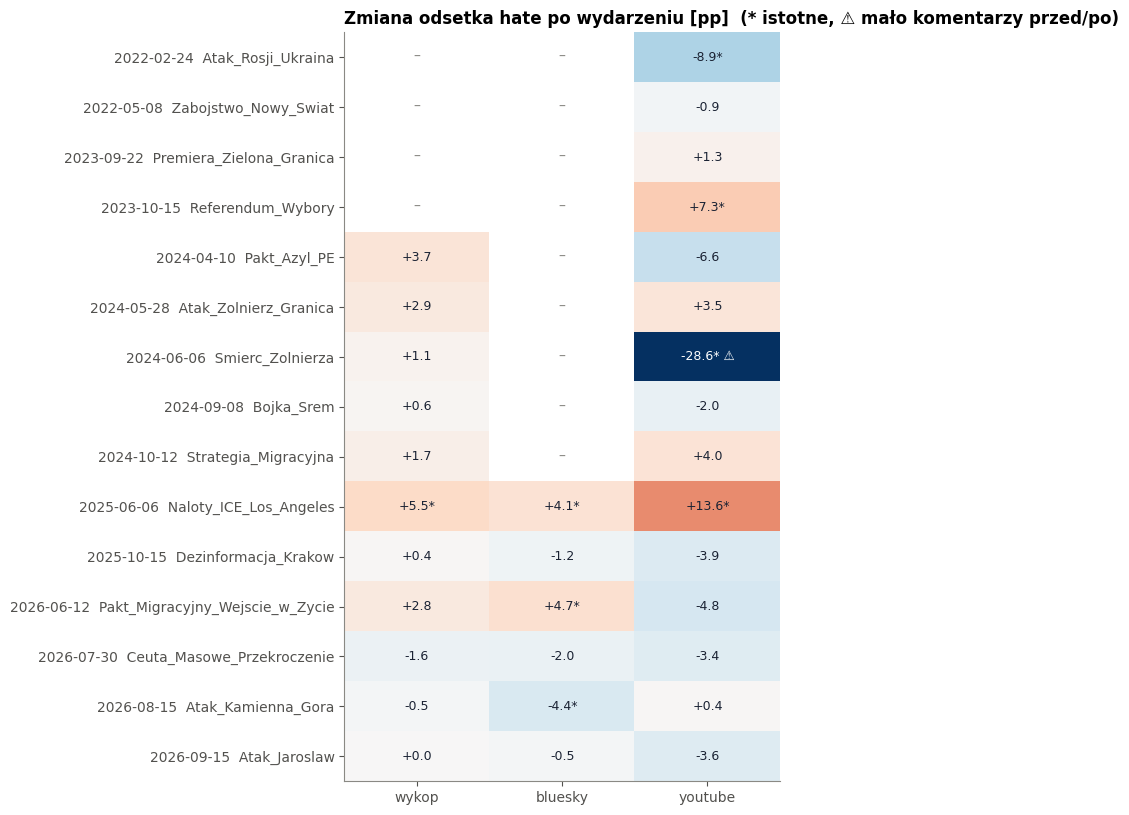

In [6]:
# mapa: zmiana pp dla każdego wydarzenia × platforma (gwiazdka = istotne po Holmie, ⚠ = niezbalansowane przed/po)
mat = eff.pivot(index="event", columns="platform", values="różnica pp").reindex(EVENT_ORDER)[PLATFORMS]
sig = eff.pivot(index="event", columns="platform", values="istotne").reindex(EVENT_ORDER)[PLATFORMS]
bal = eff.pivot(index="event", columns="platform", values="zbalansowane").reindex(EVENT_ORDER)[PLATFORMS]
lim = np.nanmax(np.abs(mat.values))
fig, ax = plt.subplots(figsize=(8, 0.45 * len(mat) + 1.5))
ax.imshow(mat.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
for (i, j), v in np.ndenumerate(mat.values):
    if np.isnan(v):
        ax.text(j, i, "–", ha="center", va="center", color=MUTED)
        continue
    mark = ("*" if sig.iloc[i, j] is True else "") + ("" if bal.iloc[i, j] is True else " ⚠")
    ax.text(j, i, f"{v:+.1f}{mark}", ha="center", va="center", fontsize=9, color="white" if abs(v) > 0.6 * lim else INK)
ax.set_xticks(range(len(PLATFORMS)), PLATFORMS)
ax.set_yticks(range(len(mat)), [f"{EVENT_DATES[e]}  {e}" for e in mat.index])
ax.grid(False)
ax.set_title("Zmiana odsetka hate po wydarzeniu [pp]  (* istotne, ⚠ mało komentarzy przed/po)")
plt.tight_layout()
fig.savefig(OUT / "h1_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### 2b. Test z README: Wilcoxon (pary przed/po) + wielkość efektu

Dla każdej pary wydarzenie × platforma: średni **dzienny** odsetek hate przed i po (dni z ≥ `MIN_DAILY_N` komentarzami).
Wilcoxon dla par (jednostka = para wydarzenie × platforma), wielkość efektu = korelacja rangowo-dwuseryjna dla par
(*r*; 0.1 mały, 0.3 średni, 0.5 duży). Liczone: wszystkie platformy razem i każda platforma osobno; wersja główna
tylko na parach zbalansowanych.

In [7]:
daily = (df.groupby(["platform", "event", "relative_day"]).agg(n=("hate", "size"), k=("hate", "sum")).reset_index())
daily["share"] = daily["k"] / daily["n"]
dd = daily[daily["n"] >= MIN_DAILY_N]
pp = (dd.assign(okres=np.where(dd["relative_day"] >= POST_FROM_DAY, "po", "przed"))
      .groupby(["platform", "event", "okres"])["share"].mean().unstack("okres").dropna())
pp = pp.join(eff.set_index(["platform", "event"])[["zbalansowane", "typ"]])
pp["zmiana pp"] = 100 * (pp["po"] - pp["przed"])


def wilcoxon_pairs(a, b):
    a, b = np.asarray(a), np.asarray(b)
    d = b - a
    d = d[d != 0]
    if len(d) < 3:
        return {"n": len(d), "W": np.nan, "p": np.nan, "r (rank-biserial)": np.nan}
    res = stats.wilcoxon(d)
    ranks = stats.rankdata(np.abs(d))
    r = (ranks[d > 0].sum() - ranks[d < 0].sum()) / ranks.sum()
    return {"n": len(d), "W": res.statistic, "p": res.pvalue, "r (rank-biserial)": r}


h1_rows = []
for scope, sub in [("wszystkie platformy", pp), *[(p, pp.loc[p]) for p in PLATFORMS if p in pp.index.get_level_values(0)]]:
    for variant, s in [("tylko zbalansowane", sub[sub["zbalansowane"]]), ("wszystkie pary", sub)]:
        w = wilcoxon_pairs(s["przed"], s["po"])
        h1_rows.append({"zakres": scope, "pary": variant, "wzrost w": f"{int((s['zmiana pp'] > 0).sum())}/{len(s)}",
                        "mediana zmiany pp": s["zmiana pp"].median(), "średnia zmiany pp": s["zmiana pp"].mean(), **w})
h1 = pd.DataFrame(h1_rows)
h1.to_csv(OUT / "h1_wilcoxon.csv", index=False, encoding="utf-8-sig")
display(fmt_p(h1.set_index(["zakres", "pary"]), 3))

wzrost w  mediana zmiany pp  średnia zmiany pp   n      W      p  r (rank-biserial)
zakres              pary                                                                                                  
wszystkie platformy tylko zbalansowane    13/31             -0.333              0.287  31  235.0  0.809             -0.052
                    wszystkie pary        13/31             -0.333              0.287  31  235.0  0.809             -0.052
wykop               tylko zbalansowane     8/11              0.856              1.294  11   13.0  0.083              0.606
                    wszystkie pary         8/11              0.856              1.294  11   13.0  0.083              0.606
bluesky             tylko zbalansowane      2/6             -0.618              0.164   6   10.0      1             -0.048
                    wszystkie pary          2/6             -0.618              0.164   6   10.0      1             -0.048
youtube             tylko zbalansowane     3/14             -2.053             -0.451  14   38.0  0.391             -0.276
                    wszystkie pary         3/14             -2.053             -0.451  14   38.0  0.391             -0.276

### 2c. Zagregowane per platforma i per wydarzenie (metaanaliza efektów losowych)

- **Per platforma:** łączny OR wszystkich wydarzeń danej platformy (DerSimonian–Laird + Hartung–Knapp, jak w notebookach zespołu).
- **Per wydarzenie:** łączny OR tego samego wydarzenia na wszystkich platformach, na których jest (globalny efekt wydarzenia).

In [8]:
def meta_random(y, se):
    y, se = np.asarray(y, float), np.asarray(se, float)
    k, w = len(y), 1 / se ** 2
    fixed = (w * y).sum() / w.sum()
    q = (w * (y - fixed) ** 2).sum()
    c = w.sum() - (w ** 2).sum() / w.sum()
    tau2 = max(0.0, (q - (k - 1)) / c) if k > 1 else 0.0
    ws = 1 / (se ** 2 + tau2)
    mu = (ws * y).sum() / ws.sum()
    if k == 1:
        return {"k": 1, "OR": np.exp(mu), "OR lo": np.exp(mu - 1.96 * se[0]), "OR hi": np.exp(mu + 1.96 * se[0]),
                "p": 2 * stats.norm.sf(abs(mu / se[0])), "I²": np.nan}
    se_hk = max(np.sqrt((ws * (y - mu) ** 2).sum() / ((k - 1) * ws.sum())), np.sqrt(1 / ws.sum()))
    t = stats.t.ppf(1 - ALPHA / 2, k - 1)
    return {"k": k, "OR": np.exp(mu), "OR lo": np.exp(mu - t * se_hk), "OR hi": np.exp(mu + t * se_hk),
            "p": 2 * stats.t.sf(abs(mu / se_hk), k - 1), "I²": max(0.0, (q - (k - 1)) / q) if q > 0 else 0.0}


agg_rows = []
for variant, e in [("zbalansowane", eff[eff["zbalansowane"]]), ("wszystkie", eff)]:
    for platform, g in e.groupby("platform"):
        agg_rows.append({"poziom": "platforma", "co": platform, "pary": variant, "średnia zmiana pp": g["różnica pp"].mean(),
                         "wzrost w": f"{int((g['różnica pp'] > 0).sum())}/{len(g)}", **meta_random(g["log OR"], g["se"])})
    agg_rows.append({"poziom": "wszystko", "co": "wszystkie platformy i wydarzenia", "pary": variant,
                     "średnia zmiana pp": e["różnica pp"].mean(), "wzrost w": f"{int((e['różnica pp'] > 0).sum())}/{len(e)}",
                     **meta_random(e["log OR"], e["se"])})
agg = pd.DataFrame(agg_rows)
agg["istotne"] = agg["p"] < ALPHA
display(fmt_p(agg.set_index(["pary", "poziom", "co"]), 3))

ev_rows = []
for event, g in eff[eff["zbalansowane"]].groupby("event"):
    ev_rows.append({"event": event, "data": EVENT_DATES[event], "typ": g["typ"].iloc[0], "platformy": ", ".join(g["platform"]),
                    "zmiany pp": ", ".join(f"{p[:2]} {v:+.1f}" for p, v in zip(g["platform"], g["różnica pp"])),
                    **meta_random(g["log OR"], g["se"])})
by_event = pd.DataFrame(ev_rows).sort_values("data")
by_event["p (Holm)"] = multipletests(by_event["p"], method="holm")[1]
by_event["istotne"] = by_event["p (Holm)"] < ALPHA
agg.to_csv(OUT / "h1_pooled_platform.csv", index=False, encoding="utf-8-sig")
by_event.to_csv(OUT / "h1_pooled_event.csv", index=False, encoding="utf-8-sig")
print("Per wydarzenie – wszystkie platformy razem (tylko pary zbalansowane):")
display(fmt_p(by_event.set_index("event"), 3))

średnia zmiana pp wzrost w   k     OR  OR lo  OR hi       p     I²  istotne
pary         poziom    co                                                                                                           
zbalansowane platforma bluesky                                       0.121      2/6   6  1.016  0.789  1.309   0.875  0.874    False
                       wykop                                         1.507     9/11  11  1.070  1.002  1.143  0.0448  0.666     True
                       youtube                                      -0.292     6/14  14  0.986  0.847  1.148   0.847  0.709    False
             wszystko  wszystkie platformy i wydarzenia              0.426    17/31  31  1.032  0.965  1.104   0.344  0.750    False
wszystkie    platforma bluesky                                       0.121      2/6   6  1.016  0.789  1.309   0.875  0.874    False
                       wykop                                         1.507     9/11  11  1.070  1.002  1.143  0.0448  0.666     True
                       youtube                                      -2.180     6/15  15  0.909  0.732  1.130   0.364  0.873    False
             wszystko  wszystkie platformy i wydarzenia             -0.481    17/32  32  0.996  0.902  1.098   0.926  0.844    False

Per wydarzenie – wszystkie platformy razem (tylko pary zbalansowane):


,data,typ,platformy,zmiany pp,k,OR,OR lo,OR hi,p,I²,p (Holm),istotne
event,,,,,,,,,,,,
Atak_Rosji_Ukraina,2022-02-24,wojna,youtube,yo -8.9,1,0.698,0.588,0.828,3.89e-05,NaN,0.000584,True
Zabojstwo_Nowy_Swiat,2022-05-08,dezinformacja,youtube,yo -0.9,1,0.965,0.775,1.201,0.751,NaN,1,False
Premiera_Zielona_Granica,2023-09-22,polityka / prawo,youtube,yo +1.3,1,1.053,0.758,1.462,0.76,NaN,1,False
Referendum_Wybory,2023-10-15,polityka / prawo,youtube,yo +7.3,1,1.345,1.125,1.607,0.00114,NaN,0.0159,True
Pakt_Azyl_PE,2024-04-10,polityka / prawo,"wykop, youtube","wy +3.7, yo -6.6",2,1.023,0.065,16.076,0.933,0.622,1,False
Atak_Zolnierz_Granica,2024-05-28,przemoc / incydent,"wykop, youtube","wy +2.9, yo +3.5",2,1.137,0.589,2.197,0.244,0.000,1,False
Smierc_Zolnierza,2024-06-06,przemoc / incydent,wykop,wy +1.1,1,1.050,0.955,1.155,0.311,NaN,1,False
Bojka_Srem,2024-09-08,przemoc / incydent,"wykop, youtube","wy +0.6, yo -2.0",2,1.016,0.442,2.335,0.848,0.000,1,False
Strategia_Migracyjna,2024-10-12,polityka / prawo,"wykop, youtube","wy +1.7, yo +4.0",2,1.098,0.522,2.312,0.356,0.000,1,False


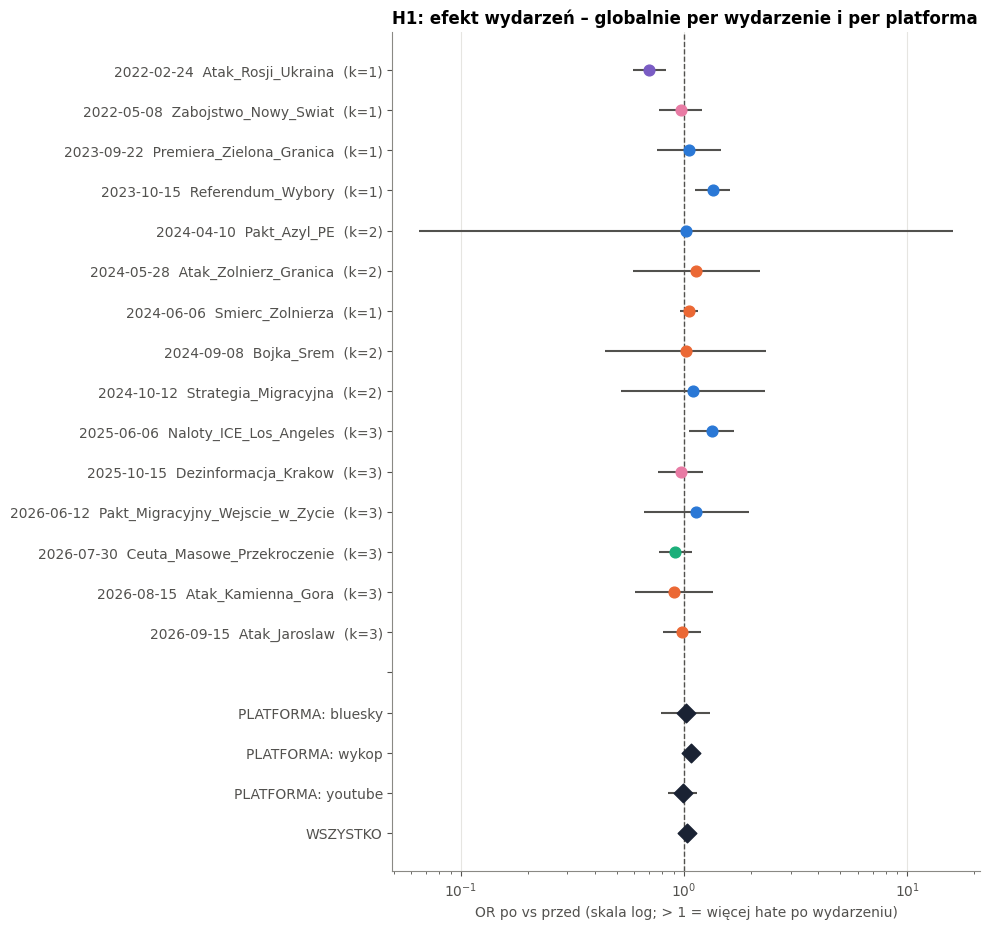

In [9]:
# forest plot per wydarzenie (globalnie) + per platforma
fig, ax = plt.subplots(figsize=(10, 0.42 * (len(by_event) + 5) + 1))
rows_plot = [(f"{r['data']}  {r['event']}  (k={r['k']})", r["OR"], r["OR lo"], r["OR hi"], TYPE_COLORS.get(r["typ"], MUTED))
             for _, r in by_event.iterrows()]
pa = agg[(agg["pary"] == "zbalansowane")]
rows_plot += [("", np.nan, np.nan, np.nan, None)]
rows_plot += [(f"PLATFORMA: {r['co']}" if r["poziom"] == "platforma" else "WSZYSTKO", r["OR"], r["OR lo"], r["OR hi"], INK)
              for _, r in pa.iterrows()]
y = np.arange(len(rows_plot))[::-1]
for yi, (lab, o, lo, hi, col) in zip(y, rows_plot):
    if np.isnan(o):
        continue
    ax.hlines(yi, lo, hi, color=INK2, lw=1.5)
    ax.scatter(o, yi, s=60 if col != INK else 90, marker="o" if col != INK else "D", color=col, zorder=3)
ax.axvline(1, ls="--", color=INK2, lw=1)
ax.set_xscale("log")
ax.set_yticks(y, [r[0] for r in rows_plot])
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("OR po vs przed (skala log; > 1 = więcej hate po wydarzeniu)")
ax.set_title("H1: efekt wydarzeń – globalnie per wydarzenie i per platforma")
plt.tight_layout()
fig.savefig(OUT / "h1_forest.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. H2 – czy siła efektu zależy od charakteru wydarzenia?

Kruskal–Wallis na zmianie (pp) par wydarzenie × platforma między typami wydarzeń, post-hoc Dunn + Holm.
⚠️ W typach jest po kilka wydarzeń – typ prawie pokrywa się z konkretnym wydarzeniem (tak jak zauważył zespół), więc wynik
ma charakter opisowy. Typy przypisane ręcznie w `EVENT_META`.

Zmiana pp wg typu (pary zbalansowane):


,count,mean,median,min,max
typ,,,,,
dezinformacja,4,-1.43,-1.15,-3.48,0.07
kryzys graniczny,3,-2.19,-1.63,-4.74,-0.19
polityka / prawo,12,2.92,2.93,-5.12,13.22
przemoc / incydent,11,-0.66,-0.45,-3.19,2.63
wojna,1,-6.71,-6.71,-6.71,-6.71


Kruskal–Wallis (typ): {'H': np.float64(6.1637), 'p': np.float64(0.1039), 'epsilon²': np.float64(0.1217), 'grup': 4, 'n': 30}


,grupa A,grupa B,z,p,p (Holm)
0,dezinformacja,kryzys graniczny,0.235,0.814,1
1,dezinformacja,polityka / prawo,-1.754,0.0794,0.388
2,dezinformacja,przemoc / incydent,-0.447,0.655,1
3,kryzys graniczny,polityka / prawo,-1.848,0.0646,0.388
4,kryzys graniczny,przemoc / incydent,-0.676,0.499,1
5,polityka / prawo,przemoc / incydent,1.802,0.0716,0.388


Kruskal–Wallis (zasięg PL vs zagranica): {'H': np.float64(0.0592), 'p': np.float64(0.8077), 'epsilon²': np.float64(-0.0324), 'grup': 2, 'n': 31}


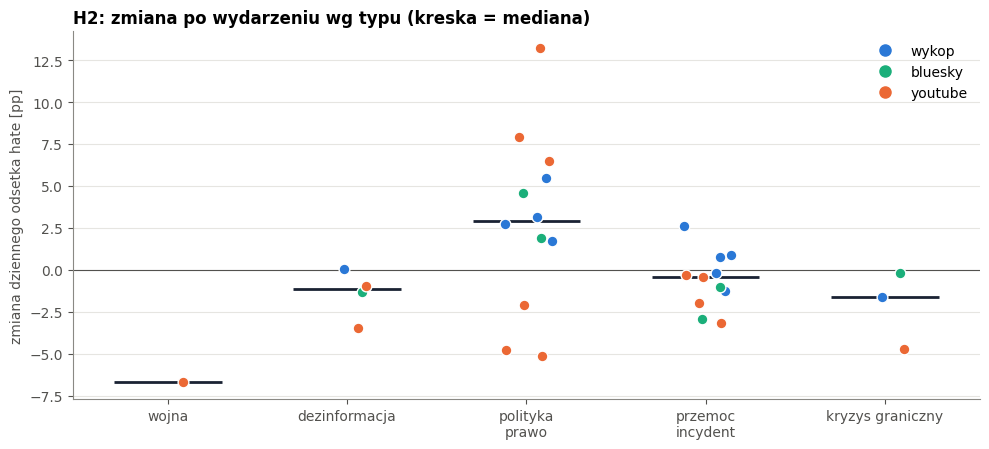

In [10]:
def dunn(groups, labels):
    allv = np.concatenate(groups)
    ranks = stats.rankdata(allv)
    n_all = len(allv)
    idx, out = 0, []
    mean_r = []
    for g in groups:
        mean_r.append(ranks[idx:idx + len(g)].mean())
        idx += len(g)
    _, counts = np.unique(allv, return_counts=True)
    tie = 1 - (counts ** 3 - counts).sum() / (n_all ** 3 - n_all) if n_all > 1 else 1
    for (i, a), (j, b) in combinations(enumerate(labels), 2):
        se = np.sqrt(tie * n_all * (n_all + 1) / 12 * (1 / len(groups[i]) + 1 / len(groups[j])))
        z = (mean_r[i] - mean_r[j]) / se
        out.append({"grupa A": a, "grupa B": b, "z": z, "p": 2 * stats.norm.sf(abs(z))})
    res = pd.DataFrame(out)
    if len(res):
        res["p (Holm)"] = multipletests(res["p"], method="holm")[1]
    return res


def kw_dunn(data, by, value="zmiana pp", min_n=2):
    g = {k: v[value].values for k, v in data.groupby(by) if len(v) >= min_n}
    if len(g) < 2:
        return None, None
    h, p = stats.kruskal(*g.values())
    n = sum(len(v) for v in g.values())
    eps2 = (h - len(g) + 1) / (n - len(g))       # epsilon² (wielkość efektu dla K–W)
    return {"H": h, "p": p, "epsilon²": eps2, "grup": len(g), "n": n}, dunn(list(g.values()), list(g.keys()))


base = pp[pp["zbalansowane"]].reset_index()
print("Zmiana pp wg typu (pary zbalansowane):")
display(base.groupby("typ")["zmiana pp"].agg(["count", "mean", "median", "min", "max"]).round(2))
res, post = kw_dunn(base, "typ")
print("Kruskal–Wallis (typ):", {k: round(v, 4) for k, v in res.items()} if res else "za mało grup")
if post is not None:
    display(fmt_p(post, 3))
h2 = pd.DataFrame([{"podział": "typ", **(res or {})}])
res_z, post_z = kw_dunn(base.assign(zasieg=base["event"].map(lambda e: EVENT_META.get(e, ("", "?"))[1])), "zasieg")
print("Kruskal–Wallis (zasięg PL vs zagranica):", {k: round(v, 4) for k, v in res_z.items()} if res_z else "za mało grup")
h2 = pd.concat([h2, pd.DataFrame([{"podział": "zasięg", **(res_z or {})}])])
h2.to_csv(OUT / "h2_kruskal.csv", index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(10, 4.6))
for xi, t in enumerate(TYPE_ORDER):
    g = base[base["typ"] == t]
    if g.empty:
        continue
    xs = xi + np.random.default_rng(SEED).uniform(-0.15, 0.15, len(g))
    for plat in PLATFORMS:
        m = g["platform"] == plat
        ax.scatter(xs[m.values], g.loc[m, "zmiana pp"], s=60, color=PLAT_COLORS[plat], edgecolor="white", zorder=3,
                   label=plat if xi == 0 else None)
    ax.hlines(g["zmiana pp"].median(), xi - 0.3, xi + 0.3, color=INK, lw=2)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xticks(range(len(TYPE_ORDER)), [t.replace(" / ", "\n") for t in TYPE_ORDER])
ax.set_ylabel("zmiana dziennego odsetka hate [pp]")
ax.set_title("H2: zmiana po wydarzeniu wg typu (kreska = mediana)")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, ms=8) for c in PLAT_COLORS.values()]
ax.legend(handles, PLAT_COLORS.keys(), loc="upper right")
plt.tight_layout()
fig.savefig(OUT / "h2_types.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. H3 – trwałość efektu: kiedy zmiana jest największa i po ilu dniach wraca do baseline?

Dla każdej pary: odsetek hate w oknach po wydarzeniu minus odsetek w baseline (dni −28…−1).
- **Friedman** – czy okna różnią się między sobą (te same pary we wszystkich oknach), post-hoc Wilcoxon + Holm,
- **każde okno vs baseline** – Wilcoxon (zmiana ≠ 0) + Holm: w którym oknie efekt przestaje być widoczny.

In [11]:
def window_share(d, lo, hi):
    w = d[d["relative_day"].between(lo, hi)]
    return (w["hate"].mean(), len(w)) if len(w) else (np.nan, 0)


wrows = []
for (platform, event), d in df.groupby(["platform", "event"]):
    b, nb = window_share(d, *BASELINE)
    row = {"platform": platform, "event": event, "baseline %": 100 * b, "n baseline": nb}
    for name, (lo, hi) in WINDOWS.items():
        s, n = window_share(d, lo, hi)
        row[name] = 100 * (s - b) if n >= MIN_PERIOD_N / 2 and nb >= MIN_PERIOD_N else np.nan
    wrows.append(row)
win = pd.DataFrame(wrows)
win.to_csv(OUT / "h3_windows.csv", index=False, encoding="utf-8-sig")
wn = list(WINDOWS)
complete = win.dropna(subset=wn)
print(f"pary z kompletem okien: {len(complete)} z {len(win)}")
display(win.groupby("platform")[wn].agg(["mean", "median"]).round(2))

h3_rows = []
for scope, sub in [("wszystkie platformy", complete), *[(p, complete[complete["platform"] == p]) for p in PLATFORMS]]:
    if len(sub) >= 3:
        fr = stats.friedmanchisquare(*[sub[w] for w in wn])
        h3_rows.append({"zakres": scope, "test": "Friedman (okna)", "n par": len(sub), "statystyka": fr.statistic, "p": fr.pvalue})
    ps = []
    for w in wn:
        s = sub[w].dropna()
        p = stats.wilcoxon(s).pvalue if len(s) >= 3 and (s != 0).any() else np.nan
        ps.append(p)
        h3_rows.append({"zakres": scope, "test": f"{w} vs baseline", "n par": len(s), "średnia zmiana pp": s.mean(),
                        "mediana zmiany pp": s.median(), "p": p})
h3 = pd.DataFrame(h3_rows)
for scope, g in h3[h3["test"].str.endswith("baseline")].groupby("zakres"):
    ok = g["p"].notna()
    h3.loc[g.index[ok], "p (Holm)"] = multipletests(g.loc[ok, "p"], method="holm")[1]
h3.to_csv(OUT / "h3_tests.csv", index=False, encoding="utf-8-sig")
display(fmt_p(h3.set_index(["zakres", "test"]), 3))

post_rows = []
for a, b in combinations(wn, 2):
    s = complete[b] - complete[a]
    post_rows.append({"okno A": a, "okno B": b, "mediana B−A pp": s.median(),
                      "p": stats.wilcoxon(s).pvalue if (s != 0).sum() >= 3 else np.nan})
post3 = pd.DataFrame(post_rows)
post3["p (Holm)"] = multipletests(post3["p"].fillna(1), method="holm")[1]
print("Post-hoc (wszystkie platformy): Wilcoxon między oknami + Holm")
display(fmt_p(post3, 3))

pary z kompletem okien: 30 z 32


dni 0–3        dni 4–7        dni 8–14        dni 15–28       
            mean median    mean median     mean median      mean median
platform                                                               
bluesky    -0.92  -0.70    0.18   0.04    -0.41  -0.59     -0.00  -0.50
wykop       0.40  -0.03    0.17  -1.61     2.47   1.35      1.61   0.77
youtube     1.07  -0.91   -2.30  -2.95     0.33  -1.24      0.89   0.79

n par  statystyka        p  średnia zmiana pp  mediana zmiany pp p (Holm)
zakres              test                                                                                            
wszystkie platformy Friedman (okna)           30       2.680    0.444                NaN                NaN         
                    dni 0–3 vs baseline       30         NaN    0.685              0.260             -0.908        1
                    dni 4–7 vs baseline       30         NaN    0.205             -1.265             -1.667    0.822
                    dni 8–14 vs baseline      30         NaN     0.44              0.771              0.950        1
                    dni 15–28 vs baseline     30         NaN    0.428              0.976              0.506        1
wykop               Friedman (okna)           11       3.327    0.344                NaN                NaN         
                    dni 0–3 vs baseline       11         NaN    0.765              0.405             -0.029        1
                    dni 4–7 vs baseline       11         NaN        1              0.173             -1.611        1
                    dni 8–14 vs baseline      11         NaN  0.00195              2.470              1.348  0.00781
                    dni 15–28 vs baseline     11         NaN   0.0537              1.613              0.769    0.161
bluesky             Friedman (okna)            6       0.400     0.94                NaN                NaN         
                    dni 0–3 vs baseline        6         NaN    0.438             -0.925             -0.697        1
                    dni 4–7 vs baseline        6         NaN        1              0.183              0.040        1
                    dni 8–14 vs baseline       6         NaN    0.844             -0.410             -0.586        1
                    dni 15–28 vs baseline      6         NaN        1             -0.004             -0.503        1
youtube             Friedman (okna)           13       2.354    0.502                NaN                NaN         
                    dni 0–3 vs baseline       13         NaN    0.946              0.684             -1.043        1
                    dni 4–7 vs baseline       13         NaN    0.127             -3.151             -2.976    0.509
                    dni 8–14 vs baseline      13         NaN    0.685             -0.121             -2.740        1
                    dni 15–28 vs baseline     13         NaN    0.946              0.889              0.790        1

Post-hoc (wszystkie platformy): Wilcoxon między oknami + Holm


,okno A,okno B,mediana B−A pp,p,p (Holm)
0,dni 0–3,dni 4–7,-0.702,0.289,1
1,dni 0–3,dni 8–14,0.872,0.371,1
2,dni 0–3,dni 15–28,2.467,0.28,1
3,dni 4–7,dni 8–14,2.010,0.0234,0.14
4,dni 4–7,dni 15–28,2.456,0.0606,0.303
5,dni 8–14,dni 15–28,0.460,0.761,1


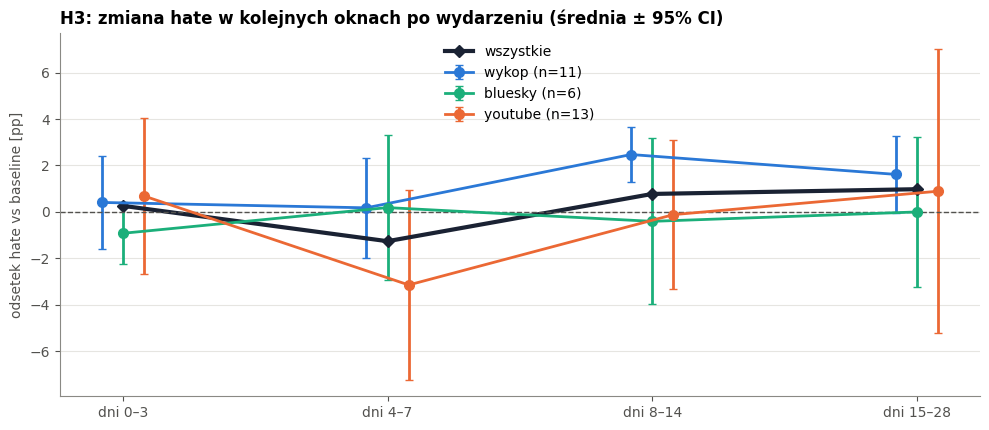

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.4))
x = np.arange(len(wn))
for i, plat in enumerate(PLATFORMS):
    s = complete[complete["platform"] == plat][wn]
    if s.empty:
        continue
    m = s.mean()
    se = s.std(ddof=1) / np.sqrt(len(s)) if len(s) > 1 else s.mean() * 0
    ax.errorbar(x + (i - 1) * 0.08, m, yerr=1.96 * se, marker="o", ms=7, capsize=3, lw=2, color=PLAT_COLORS[plat],
                label=f"{plat} (n={len(s)})")
allm = complete[wn].mean()
ax.plot(x, allm, color=INK, lw=3, marker="D", label="wszystkie")
ax.axhline(0, color=INK2, lw=1, ls="--")
ax.set_xticks(x, wn)
ax.set_ylabel("odsetek hate vs baseline [pp]")
ax.set_title("H3: zmiana hate w kolejnych oknach po wydarzeniu (średnia ± 95% CI)")
ax.legend()
plt.tight_layout()
fig.savefig(OUT / "h3_windows.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. H4 – różnice między platformami

1. **Poziom hate** (baseline, przed wydarzeniem) – Kruskal–Wallis między platformami + Dunn/Holm.
2. **Reakcja na wydarzenie** (zmiana pp) – Kruskal–Wallis między platformami + Dunn/Holm.
3. **Te same wydarzenia na 3 platformach** – Friedman na zmianie pp (wydarzenia obecne na wszystkich platformach, zbalansowane).

Poziom hate przed wydarzeniem [%] wg platformy:


,count,mean,50%,min,max
platform,,,,,
bluesky,6.0,19.21,18.98,16.75,21.92
wykop,11.0,32.75,33.47,28.45,36.10
youtube,15.0,47.41,45.88,39.19,71.43


,grupa A,grupa B,z,p,p (Holm)
0,bluesky,wykop,-1.785,0.0742,0.0742
1,bluesky,youtube,-4.745,2.09e-06,6.26e-06
2,wykop,youtube,-3.491,0.000481,0.000962


Zmiana po wydarzeniu [pp] wg platformy (pary zbalansowane):


,count,mean,50%,min,max
platform,,,,,
bluesky,6.0,0.16,-0.62,-2.93,4.57
wykop,11.0,1.29,0.86,-1.63,5.45
youtube,14.0,-0.45,-2.05,-6.71,13.22


,grupa A,grupa B,z,p,p (Holm)
0,bluesky,wykop,-0.837,0.402,0.701
1,bluesky,youtube,0.934,0.35,0.701
2,wykop,youtube,2.186,0.0288,0.0865


platform,bluesky,wykop,youtube
event,,,
Atak_Jaroslaw,-1.04,-1.28,-3.19
Atak_Kamienna_Gora,-2.93,-0.22,-0.33
Ceuta_Masowe_Przekroczenie,-0.19,-1.63,-4.74
Dezinformacja_Krakow,-1.31,0.07,-0.98
Naloty_ICE_Los_Angeles,1.90,5.45,13.22
Pakt_Migracyjny_Wejscie_w_Zycie,4.57,2.73,-4.81


,H,p,epsilon²,grup,n
porównanie,,,,,
poziom hate (baseline),26.3693,1.88e-06,0.8403,3.0,32.0
zmiana po wydarzeniu (pp),4.7993,0.0908,0.1000,3.0,31.0
Friedman – te same wydarzenia na 3 platformach (n=6),1.3333,0.513,NaN,NaN,NaN


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/tmp/ipykernel_11/1945755028.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(vals, labels=PLATFORMS, patch_artist=True, widths=0.5, medianprops={"color": INK, "lw": 2})
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/tmp/ipykernel_11/1945755028.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(vals, labels=PLATFORMS, patch_artist=True, widths=0.5, medianprops={"color": INK, "lw": 2})


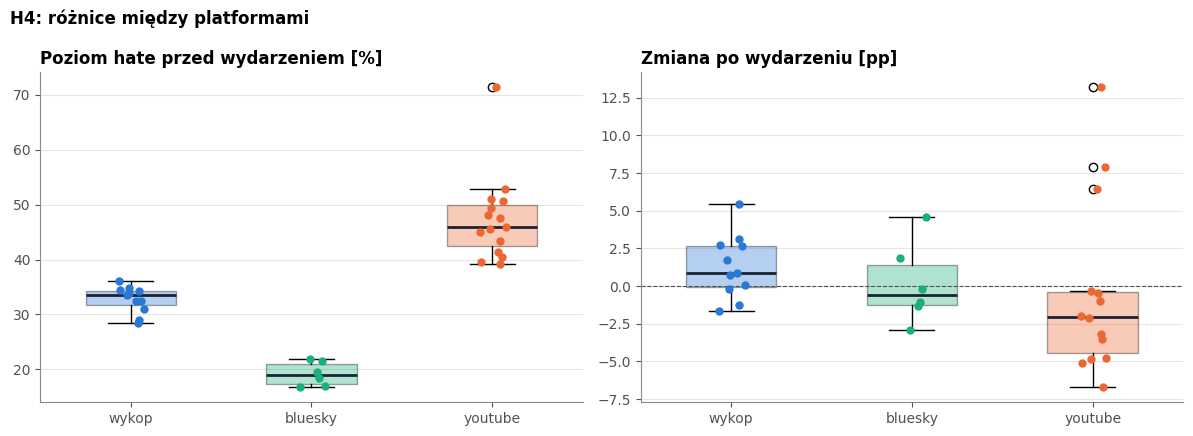

In [13]:
h4_rows = []
lvl = win.dropna(subset=["baseline %"])
res_l, post_l = kw_dunn(lvl.assign(v=lvl["baseline %"]), "platform", value="v")
h4_rows.append({"porównanie": "poziom hate (baseline)", **(res_l or {})})
print("Poziom hate przed wydarzeniem [%] wg platformy:")
display(lvl.groupby("platform")["baseline %"].describe()[["count", "mean", "50%", "min", "max"]].round(2))
if post_l is not None:
    display(fmt_p(post_l, 3))
res_c, post_c = kw_dunn(base, "platform")
h4_rows.append({"porównanie": "zmiana po wydarzeniu (pp)", **(res_c or {})})
print("Zmiana po wydarzeniu [pp] wg platformy (pary zbalansowane):")
display(base.groupby("platform")["zmiana pp"].describe()[["count", "mean", "50%", "min", "max"]].round(2))
if post_c is not None:
    display(fmt_p(post_c, 3))
wide = base.pivot(index="event", columns="platform", values="zmiana pp").dropna()
if len(wide) >= 3 and wide.shape[1] == 3:
    fr = stats.friedmanchisquare(*[wide[c] for c in wide.columns])
    h4_rows.append({"porównanie": f"Friedman – te same wydarzenia na 3 platformach (n={len(wide)})", "H": fr.statistic, "p": fr.pvalue})
    display(wide.round(2))
h4 = pd.DataFrame(h4_rows)
h4.to_csv(OUT / "h4_platforms.csv", index=False, encoding="utf-8-sig")
display(fmt_p(h4.set_index("porównanie"), 4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, (data, col, title) in zip(axes, [(lvl, "baseline %", "Poziom hate przed wydarzeniem [%]"),
                                          (base, "zmiana pp", "Zmiana po wydarzeniu [pp]")]):
    vals = [data.loc[data["platform"] == p, col].dropna() for p in PLATFORMS]
    bp = ax.boxplot(vals, labels=PLATFORMS, patch_artist=True, widths=0.5, medianprops={"color": INK, "lw": 2})
    for patch, p in zip(bp["boxes"], PLATFORMS):
        patch.set_facecolor(PLAT_COLORS[p]); patch.set_alpha(0.35)
    for i, (v, p) in enumerate(zip(vals, PLATFORMS), 1):
        ax.scatter(np.full(len(v), i) + np.random.default_rng(SEED).uniform(-0.08, 0.08, len(v)), v, color=PLAT_COLORS[p], s=25, zorder=3)
    if col == "zmiana pp":
        ax.axhline(0, color=INK2, lw=0.8, ls="--")
    ax.set_title(title)
plt.suptitle("H4: różnice między platformami", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
fig.savefig(OUT / "h4_platforms.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Przebieg dzienny – wydarzenia z największą zmianą

Dzienny odsetek hate (średnia 7-dniowa, wyśrodkowana) dla par z największym wzrostem i spadkiem.

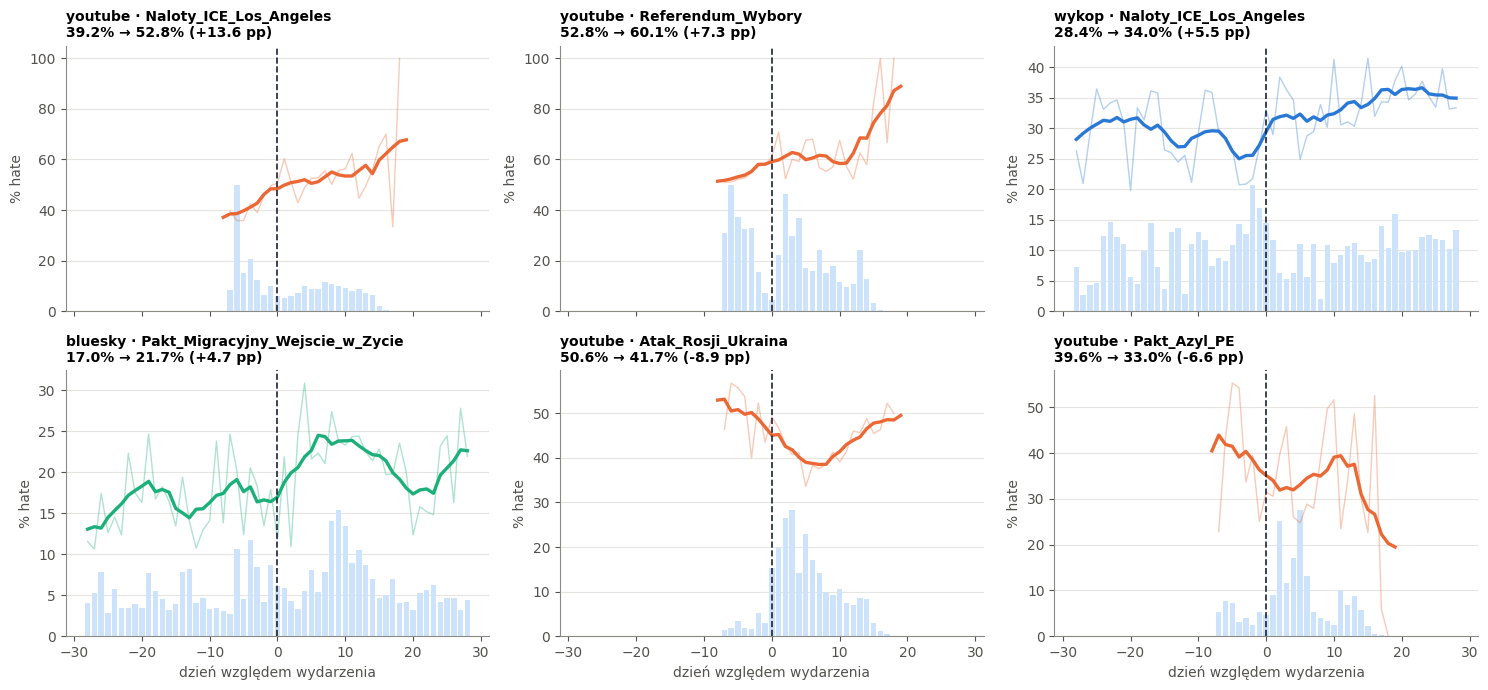

Najwyższy dzienny odsetek hate po wydarzeniu (top 10):


,platform,event,relative_day,n,szczyt %,przed %,szczyt − przed pp
0,youtube,Referendum_Wybory,15,39,82.1,52.8,29.3
3,youtube,Naloty_ICE_Los_Angeles,15,46,65.2,39.2,26.0
1,youtube,Premiera_Zielona_Granica,16,54,68.5,48.1,20.4
5,youtube,Atak_Zolnierz_Granica,3,425,60.9,41.4,19.5
12,wykop,Strategia_Migracyjna,21,313,53.0,33.5,19.5
26,bluesky,Ceuta_Masowe_Przekroczenie,6,60,38.3,21.6,16.7
8,youtube,Strategia_Migracyjna,16,37,56.8,40.4,16.4
2,youtube,Zabojstwo_Nowy_Swiat,1,535,65.8,50.9,14.9
16,wykop,Pakt_Migracyjny_Wejscie_w_Zycie,21,248,49.2,34.5,14.7
6,youtube,Atak_Kamienna_Gora,15,125,60.0,45.6,14.4


In [14]:
top_up = eff[eff["zbalansowane"]].nlargest(4, "różnica pp")
top_dn = eff[eff["zbalansowane"]].nsmallest(2, "różnica pp")
sel = pd.concat([top_up, top_dn])
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for ax, (_, r) in zip(axes.flat, sel.iterrows()):
    d = daily[(daily["platform"] == r["platform"]) & (daily["event"] == r["event"])].set_index("relative_day")
    d = d.reindex(range(-28, 29))
    sh = 100 * d["k"] / d["n"]
    ax.bar(d.index, d["n"].fillna(0) / d["n"].max() * np.nanmax(sh) * 0.5, color="#cde2fb", width=0.8, label="liczba komentarzy (skala)")
    ax.plot(d.index, sh, color=PLAT_COLORS[r["platform"]], alpha=0.35, lw=1)
    ax.plot(d.index, sh.rolling(7, center=True, min_periods=3).mean(), color=PLAT_COLORS[r["platform"]], lw=2.4)
    ax.axvline(0, ls="--", color=INK, lw=1.2)
    ax.set_title(f"{r['platform']} · {r['event']}\n{r['przed %']:.1f}% → {r['po %']:.1f}% ({r['różnica pp']:+.1f} pp)", fontsize=10)
    ax.set_ylabel("% hate")
for ax in axes[-1]:
    ax.set_xlabel("dzień względem wydarzenia")
plt.tight_layout()
fig.savefig(OUT / "daily_top_changes.png", dpi=150, bbox_inches="tight")
plt.show()

# szczyty: dzień z najwyższym dziennym odsetkiem hate po wydarzeniu (dni z ≥ 30 komentarzami)
peaks = (daily[(daily["relative_day"] >= 0) & (daily["n"] >= 30)]
         .sort_values("share", ascending=False).groupby(["platform", "event"]).head(1))
peaks = peaks.merge(eff[["platform", "event", "przed %"]], on=["platform", "event"])
peaks["szczyt %"] = (100 * peaks["share"]).round(1)
peaks["szczyt − przed pp"] = (peaks["szczyt %"] - peaks["przed %"]).round(1)
peaks["przed %"] = peaks["przed %"].round(1)
print("Najwyższy dzienny odsetek hate po wydarzeniu (top 10):")
display(peaks.sort_values("szczyt − przed pp", ascending=False).head(10)[["platform", "event", "relative_day", "n", "szczyt %", "przed %", "szczyt − przed pp"]])

## 7. Etykiety LLM zespołu (`hate`, `hate_migrant`, `migrant`) i porównanie LLM vs model

Etykiety LLM (Ollama, `scripts/topic_sample.py`) są w `data/interim/<platforma>/<wydarzenie>/labeled/comments.csv` (DVC).
Jeśli są pobrane, sekcja liczy: (a) zgodność LLM z gold standardem dla `hate` (do porównania z modelem z sekcji 1),
(b) zgodność LLM z modelem na wspólnych komentarzach, (c) H1 dla `hate_migrant` z LLM.

In [15]:
def to_bool(s):
    return s.astype(str).str.strip().str.lower().isin(["true", "1", "1.0"])


llm_frames = []
for platform in PLATFORMS:
    for d in sorted((ROOT / "data" / "interim" / platform).glob("*/")):
        f = d / "labeled" / "comments.csv"
        if f.exists():
            x = pd.read_csv(f, dtype={"comment_id": str})
            if "llm_is_hate_general" in x:
                x["platform"], x["event"] = platform, d.name[11:]
                x["hate_migrant_llm"] = to_bool(x["llm_is_hate_migrants"]) | to_bool(x.get("hate_migrants_auto", pd.Series(False, index=x.index)))
                x["hate_llm"] = to_bool(x["llm_is_hate_general"]) | to_bool(x.get("hate_auto", pd.Series(False, index=x.index))) | x["hate_migrant_llm"]
                x["migrant_llm"] = to_bool(x["llm_is_about_migration"])
                llm_frames.append(x[["platform", "event", "comment_id", "hate_llm", "hate_migrant_llm", "migrant_llm"]])
LLM = pd.concat(llm_frames, ignore_index=True) if llm_frames else None
if LLM is None:
    print("TBD: brak labeled/ (etykiet LLM) – po `dvc push` zespołu: `dvc pull`, potem odpal ten notebook ponownie.")
    print("Wyniki LLM dla Wykopu (7 wydarzeń) są w notebooku zespołu notebooks/hate_analysis/wykop/all_events_hate_analysis.ipynb.")
else:
    print(f"etykiety LLM: {len(LLM):,} komentarzy z {LLM.groupby(['platform', 'event']).ngroups} par")
    gold = pd.read_csv(ROOT / "data" / "annotation" / "gold" / "gold.csv", dtype=str, keep_default_na=False)
    g = gold.merge(LLM, left_on=["platform", "comment_id"], right_on=["platform", "comment_id"], how="inner")
    if len(g):
        y, p = g["hate"].astype(int), g["hate_llm"].astype(int)
        tp, fp, fn = int(((p == 1) & (y == 1)).sum()), int(((p == 1) & (y == 0)).sum()), int(((p == 0) & (y == 1)).sum())
        f1 = 2 * tp / (2 * tp + fp + fn) if tp else 0
        print(f"LLM vs gold (hate): n = {len(g)}, F1 = {f1:.3f}, accuracy = {(y == p).mean():.3f} "
              "(uwaga: gold zbudowany z anotacji LLM – porównanie zawyża wynik LLM)")
    both = df.merge(LLM, on=["platform", "event", "comment_id"], how="inner")
    if len(both):
        print(f"model vs LLM na wspólnych komentarzach: n = {len(both):,}, zgodność = {(both['hate'] == both['hate_llm']).mean():.3f}, "
              f"odsetek hate: model {both['hate'].mean():.3f} vs LLM {both['hate_llm'].mean():.3f}")
        rows = []
        for (platform, event), d in both.groupby(["platform", "event"]):
            for lab in ["hate_llm", "hate_migrant_llm"]:
                pre, post = d.loc[d["po"] == 0, lab], d.loc[d["po"] == 1, lab]
                rows.append({"platform": platform, "event": event, "etykieta": lab, "przed %": 100 * pre.mean(),
                             "po %": 100 * post.mean(), "różnica pp": 100 * (post.mean() - pre.mean())})
        llm_eff = pd.DataFrame(rows)
        llm_eff.to_csv(OUT / "llm_effects.csv", index=False, encoding="utf-8-sig")
        display(llm_eff.pivot_table(index=["platform", "event"], columns="etykieta", values="różnica pp").round(2))

TBD: brak labeled/ (etykiet LLM) – po `dvc push` zespołu: `dvc pull`, potem odpal ten notebook ponownie.
Wyniki LLM dla Wykopu (7 wydarzeń) są w notebooku zespołu notebooks/hate_analysis/wykop/all_events_hate_analysis.ipynb.


## 8. „Smaczki” – słowa w hejcie po wydarzeniach z największym wzrostem

Słowa, które najbardziej rosną w komentarzach `hate` po wydarzeniu (ważony log-odds z priorem Dirichleta, Monroe i in. 2008,
jak w notebookach zespołu) dla par z największym istotnym wzrostem, plus koncentracja hejtu wśród autorów.

In [16]:
STOPWORDS_PL = set('''
a aby ach acz aczkolwiek aj albo ale ależ ani aż bardziej bardzo bez bo bowiem by byli bym bynajmniej być był była było były będzie będą
cali cała cały chce chcą ci cię ciebie co cokolwiek coraz coś czasami czasem czemu czy czyli często daleko dla dlaczego dlatego do dobrze
dokąd dość dużo dwa dwaj dwie dwoje dziś dzisiaj gdy gdyby gdyż gdzie gdziekolwiek gdzieś go i ich ile im inna inne inny innych iż ja ją
jak jakaś jakby jaki jakichś jakie jakiś jakiż jakkolwiek jako jakoś je jeden jedna jedno jednak jednakże jego jej jemu jest jestem jeszcze
jeśli jeżeli już ją każdy kiedy kilka kimś kto ktokolwiek ktoś która które którego której który których którym którzy ku lat lecz lub
ma mają mam mamy mało mi mimo między mną mnie mogą moi moim moja moje może możliwe można mój mu musi my na nad nam nami nas nasi nasz nasza
nasze naszego naszych natomiast natychmiast nawet nic nich nie niech niego niej niemu nigdy nim nimi niż no o obok od około on ona one oni
ono oraz oto owszem pan pana pani po pod podczas pomimo ponad ponieważ powinien powinna powinni powinno poza prawie przecież przed przede
przedtem przez przy roku również sam sama są się skąd sobie sobą sposób swoje ta tak taka taki takie także tam te tego tej temu ten teraz
też to tobą tobie toteż trzeba tu tutaj twoi twoim twoja twoje twym twój ty tych tylko tym u w wam wami was wasz wasza wasze we według
wiele wielu więc więcej wszyscy wszystkich wszystkie wszystkim wszystko wtedy wy właśnie z za zapewne zawsze ze zł znowu znów został żaden
żadna żadne żadnych że żeby tez juz sie jak ktory ktora ktore bylo byl beda bedzie moze takze zeby ze tylko wiec niz przez tego tym jeszcze
tych tej mnie mieć mają ma mial miał było będą bylo były jakis jakies cos nikt nikogo niczego wszystkiego swój swoją swojej swoich swoim
naszym tymi takich takiej takim tamtych coś ktoś kogoś czegoś bym byś byście byśmy będę będziesz będziemy jestes jesteś jesteśmy
http https www com html pdf amp quot xd xdd xddd lenny bo tam tu oni ich sa sā też dla gdzie potem teraz chyba raczej
'''.split())

URL_RE = re.compile(r"https?://\S+|www\.\S+|@\w+")
TOKEN_RE = re.compile(r"[a-ząćęłńóśźż]{3,}")


def count_words(texts):
    return Counter(t for txt in texts for t in TOKEN_RE.findall(URL_RE.sub(" ", txt.lower())) if t not in STOPWORDS_PL)


def log_odds(c1, c2, prior, min_count=5):
    n1, n2, a0 = sum(c1.values()), sum(c2.values()), sum(prior.values())
    rows = []
    for w, y1 in c1.items():
        if y1 < min_count:
            continue
        a, y2 = prior[w], c2.get(w, 0)
        delta = np.log((y1 + a) / (n1 + a0 - y1 - a)) - np.log((y2 + a) / (n2 + a0 - y2 - a))
        rows.append((w, y1, y2, delta / np.sqrt(1 / (y1 + a) + 1 / (y2 + a))))
    return pd.DataFrame(rows, columns=["słowo", "po", "przed", "z"]).sort_values("z", ascending=False)


spicy = eff[eff["istotne"] & (eff["różnica pp"] > 0) & eff["zbalansowane"]].sort_values("różnica pp", ascending=False)
words = {}
for _, r in spicy.iterrows():
    h = df[(df["platform"] == r["platform"]) & (df["event"] == r["event"]) & (df["hate"] == 1)]
    c_pre, c_post = count_words(h.loc[h["po"] == 0, "text"]), count_words(h.loc[h["po"] == 1, "text"])
    lo_ = log_odds(c_post, c_pre, c_pre + c_post).head(TOP_N_WORDS)
    words[f"{r['platform']} · {r['event']} ({r['różnica pp']:+.1f} pp)"] = [f"{w} ({a}/{b})" for w, a, b in zip(lo_["słowo"], lo_["po"], lo_["przed"])]
if words:
    tab = pd.DataFrame({k: v + [""] * (TOP_N_WORDS - len(v)) for k, v in words.items()}, index=range(1, TOP_N_WORDS + 1))
    print("Słowa rosnące w hejcie po wydarzeniu (w nawiasie: liczba po / przed):")
    display(tab)
    tab.to_csv(OUT / "spicy_words.csv", encoding="utf-8-sig")

conc = []
for platform, g in df[df["hate"] == 1].groupby("platform"):
    per = g.dropna(subset=["author_id"]).groupby("author_id").size().sort_values(ascending=False)
    top = max(1, int(np.ceil(0.1 * len(per))))
    conc.append({"platform": platform, "autorów hejtu": len(per) or "brak author_id",
                 "top 10% autorów pisze": per.head(top).sum() / per.sum() if len(per) else np.nan,
                 "odsetek hejtu ze słownika": (g["label_source"] == "slownik").mean()})
display(pd.DataFrame(conc).set_index("platform").round(3))

Słowa rosnące w hejcie po wydarzeniu (w nawiasie: liczba po / przed):


,youtube · Naloty_ICE_Los_Angeles (+13.6 pp),youtube · Referendum_Wybory (+7.3 pp),wykop · Naloty_ICE_Los_Angeles (+5.5 pp),bluesky · Pakt_Migracyjny_Wejscie_w_Zycie (+4.7 pp),bluesky · Naloty_ICE_Los_Angeles (+4.1 pp)
1,izrael (148/3),głosowali (49/1),niemcy (139/32),policja (12/0),bąkiewicza (22/1)
2,iran (105/0),wybrali (29/0),pracy (107/34),gorzej (16/2),faszyzm (16/0)
3,izraela (56/6),tusk (301/121),iran (22/0),galizien (9/0),służby (24/4)
4,rosja (70/12),suwerenność (31/3),dzieci (98/33),idiota (9/0),dzieje (18/2)
5,atak (31/1),będziecie (48/9),rząd (87/28),debile (8/0),hołownia (12/0)
6,wojny (80/18),niemiec (117/38),kontrole (19/0),prawica (24/6),bojówek (12/0)
7,ukraina (64/12),życzę (23/1),murzyni (21/1),lekarzy (14/2),policji (12/0)
8,republika (35/3),emigrantow (26/2),murzynów (45/10),wiesz (11/1),granicy (48/18)
9,iranu (24/0),muzułmańskich (22/1),legalnych (23/3),sukcesu (7/0),razu (9/0)
10,broni (39/5),szkoda (45/9),pracować (32/7),granice (7/0),siemoniaka (9/0)


,autorów hejtu,top 10% autorów pisze,odsetek hejtu ze słownika
platform,,,
bluesky,1321,0.459,0.026
wykop,9859,0.517,0.087
youtube,brak author_id,NaN,0.122


## 9. Podsumowanie hipotez (generowane automatycznie)

In [17]:
def verdict_row(h, ok, txt):
    return {"hipoteza": h, "wynik": "potwierdzona" if ok is True else ("odrzucona / brak dowodów" if ok is False else "częściowo / TBD"),
            "uzasadnienie": txt}


w_all = h1[(h1["zakres"] == "wszystkie platformy") & (h1["pary"] == "tylko zbalansowane")].iloc[0]
m_all = agg[(agg["poziom"] == "wszystko") & (agg["pary"] == "zbalansowane")].iloc[0]
sig_units = eff[eff["istotne"] & eff["zbalansowane"]]
plat_sig = agg[(agg["poziom"] == "platforma") & (agg["pary"] == "zbalansowane") & agg["istotne"]]["co"].tolist()
h1_ok = bool(m_all["p"] < ALPHA) if not np.isnan(m_all["p"]) else None
h1_txt = (f"Wilcoxon (pary przed/po, n={int(w_all['n'])}): p={w_all['p']:.3g}, r={w_all['r (rank-biserial)']:.2f}; "
          f"metaanaliza wszystkich par: OR={m_all['OR']:.2f} [{m_all['OR lo']:.2f}; {m_all['OR hi']:.2f}], p={m_all['p']:.3g}; "
          f"istotne zmiany w {len(sig_units)} z {int(eff['zbalansowane'].sum())} par "
          f"({', '.join('{}/{} {:+.1f}pp'.format(r['platform'], r['event'], r['różnica pp']) for _, r in sig_units.iterrows())}); "
          f"istotny łączny efekt na platformie: {', '.join(plat_sig) or 'żadnej'}")
if h1_ok is False and len(sig_units):
    h1_ok = None
rows = [verdict_row("H1 wpływ wydarzeń", h1_ok, h1_txt)]
h2_p = h2.iloc[0].get("p", np.nan)
rows.append(verdict_row("H2 charakter wydarzenia", bool(h2_p < ALPHA) if not pd.isna(h2_p) else None,
                        f"Kruskal–Wallis (typ): p={h2_p:.3g}; typy ≈ pojedyncze wydarzenia – wynik opisowy"))
h3w = h3[(h3["zakres"] == "wszystkie platformy") & h3["test"].str.endswith("baseline")]
h3f = h3[(h3["zakres"] == "wszystkie platformy") & (h3["test"] == "Friedman (okna)")]
h3_txt = "; ".join(f"{r['test'].split(' vs')[0]}: {r['średnia zmiana pp']:+.2f} pp (p Holm={r.get('p (Holm)', np.nan):.3g})" for _, r in h3w.iterrows())
fr_p = h3f["p"].iloc[0] if len(h3f) else np.nan
first = h3w["średnia zmiana pp"].iloc[0] if len(h3w) else np.nan
h3_ok = None if pd.isna(fr_p) else bool(fr_p < ALPHA and first == h3w["średnia zmiana pp"].max())
rows.append(verdict_row("H3 trwałość efektu", h3_ok, f"Friedman p={fr_p:.3g}; " + h3_txt))
h4_lvl = h4.iloc[0].get("p", np.nan)
h4_chg = h4.iloc[1].get("p", np.nan) if len(h4) > 1 else np.nan
rows.append(verdict_row("H4 różnice między platformami", None if pd.isna(h4_chg) else bool(h4_lvl < ALPHA or h4_chg < ALPHA),
                        f"poziom hate: K–W p={h4_lvl:.3g}; reakcja na wydarzenie: K–W p={h4_chg:.3g}"))
summary = pd.DataFrame(rows)
summary.to_csv(OUT / "hypotheses_summary.csv", index=False, encoding="utf-8-sig")
pd.set_option("display.max_colwidth", 400)
display(summary.set_index("hipoteza"))
print(f"\nModel: {MODEL_NAME}, F1 na gold = {BEST.get('f1')}. Wyniki w {OUT.relative_to(ROOT)}/")

,wynik,uzasadnienie
hipoteza,,
H1 wpływ wydarzeń,częściowo / TBD,"Wilcoxon (pary przed/po, n=31): p=0.809, r=-0.05; metaanaliza wszystkich par: OR=1.03 [0.97; 1.10], p=0.344; istotne zmiany w 7 z 31 par (bluesky/Atak_Kamienna_Gora -4.4pp, bluesky/Naloty_ICE_Los_Angeles +4.1pp, bluesky/Pakt_Migracyjny_Wejscie_w_Zycie +4.7pp, wykop/Naloty_ICE_Los_Angeles +5.5pp, youtube/Atak_Rosji_Ukraina -8.9pp, youtube/Naloty_ICE_Los_Angeles +13.6pp, youtube/Referendum_Wybor..."
H2 charakter wydarzenia,odrzucona / brak dowodów,Kruskal–Wallis (typ): p=0.104; typy ≈ pojedyncze wydarzenia – wynik opisowy
H3 trwałość efektu,odrzucona / brak dowodów,Friedman p=0.444; dni 0–3: +0.26 pp (p Holm=1); dni 4–7: -1.27 pp (p Holm=0.822); dni 8–14: +0.77 pp (p Holm=1); dni 15–28: +0.98 pp (p Holm=1)
H4 różnice między platformami,potwierdzona,poziom hate: K–W p=1.88e-06; reakcja na wydarzenie: K–W p=0.0908



Model: HerBERT-HS, F1 na gold = 0.794. Wyniki w reports/final/


## 10. Czego jeszcze brakuje (do uzupełnienia przez zespół)

1. **Etykiety LLM (`labeled/`) w DVC** – foldery `data/interim/wykop/*/labeled` są w git (`*.dvc`), ale nie zostały wysłane
   na Google Drive (`dvc push`). Bez nich sekcja 7 się nie liczy.
2. **Gold standard dla LLM (Ollama)** – porównać etykiety `topic_sample.py` z `data/annotation/gold/gold.csv` (F1, macierz
   pomyłek, per platforma), żeby ocenić, czy LLM czy HerBERT lepiej oddaje `hate` (sekcja 7 to liczy, gdy są dane).
   Uwaga: gold był anotowany przez LLM (Claude, Gemini) – warto dołożyć przegląd części przypadków przez osoby z zespołu.
3. **Etykiety LLM dla Bluesky i YouTube** – analizy zespołu (`notebooks/hate_analysis/`) są tylko dla Wykopu; dla
   `hate_migrant` i `migrant` na Bluesky i YouTube trzeba puścić `topic_sample.py` (LLM) i analogiczne notebooki.
4. **`hate_migrant` na wszystkich platformach** – nasz klasyfikator daje tylko `hate`; H1–H4 dla hejtu wobec migrantów wymagają
   etykiet LLM (pkt 3).
5. **Niezbalansowane okresy na YouTube** – komentarze zbierane pod filmami z okolic wydarzenia, więc okres „przed” ma czasem
   kilka–kilkaset komentarzy. Do rozważenia: osobne okno zbierania dla „przed” albo analiza tylko par zbalansowanych (tak jest tu).
6. **Małe wydarzenia na Bluesky (2024)** – 12–64 komentarze w temacie; pominięte (< `MIN_EVENT_N`).
7. **Typy wydarzeń** – przypisane ręcznie (`EVENT_META`); przy kilku wydarzeniach na typ H2 jest tylko opisowe.
8. **Wnioski** – opis wyników w raporcie / preprincie na podstawie tego notebooka.